# Profils des joueurs d’Auckland FC — Zone 14

Ce notebook identifie les **trois joueurs les plus impliqués dans la zone 14** sur les quatre matchs étudiés, puis décrit leur **profil saisonnier** grâce aux données de passes, de courses sans ballon et d’activité physique de SkillCorner.

Les fonctions réutilisables sont dans `src/fonctions_zone14.py` et `src/fonctions_profils.py`. Les tableaux et leur interprétation restent dans le notebook.

## 1. Importation des fonctions

Le notebook est autonome : il ne dépend pas des variables créées dans `03_analyse_zone14.ipynb`. Il réutilise simplement les mêmes fonctions Python.

In [13]:
import pandas as pd
import s3fs
import json
import sys
from pathlib import Path

#on indique le chemin du dossier src
if Path('src').exists():
    sys.path.append('src')
else:
    sys.path.append('../src')

from fonctions_zone14 import (
    passes_depuis_zone14,
    frappes_depuis_zone14,
    passes_vers_zone14,
    courses_vers_zone14,
    courses_depuis_zone14
)
from fonctions_profils import (
    compter_actions_joueurs, 
    tableau_percentiles,
    tableau_identite, 
    tableau_profils, 
    graphique_percentiles
)

## 2. Chargement des données

Nous utilisons les mêmes quatre matchs que dans l’analyse de la zone 14, puis les trois bases de statistiques saisonnières. Les joueurs présents sur **au moins trois matchs** sont conservés, comme dans le premier notebook.

In [14]:
fs = s3fs.S3FileSystem(
    endpoint_url='https://minio.lab.sspcloud.fr',
    client_kwargs={'region_name': 'us-east-1'}
)

ids_matchs = [1886347, 1899585, 2015213, 2017461]
matchs = {}

for id_match in ids_matchs:
    evenements = pd.read_parquet(
        f's3://lfaivre/diffusion/{id_match}_dynamic_events.parquet',
        filesystem=fs
    )
    with fs.open(f's3://lfaivre/diffusion/{id_match}_match.json', 'r') as fichier:
        infos = json.load(fichier)
    nom_match = infos['home_team']['name'] + ' - ' + infos['away_team']['name']
    matchs[nom_match] = (infos, evenements)

id_auckland = 4177
print('Nombre de matchs chargés :', len(matchs))

Nombre de matchs chargés : 4


In [15]:
#on charge les bases de saison
obr = pd.read_parquet(
    's3://lfaivre/diffusion/aus1league_obraggregates_20242025.parquet',
    filesystem=fs
)
passing = pd.read_parquet(
    's3://lfaivre/diffusion/aus1league_passingaggregates_20242025.parquet',
    filesystem=fs
)
physical = pd.read_parquet(
    's3://lfaivre/diffusion/aus1league_physicalaggregates_20242025.parquet',
    filesystem=fs
)

MIN_MATCHES = 3
pas = passing.loc[passing['performance_count'] >= MIN_MATCHES].copy()
courses = obr.loc[obr['performance_count'] >= MIN_MATCHES].copy()
phys = physical.loc[physical['count_match'] >= MIN_MATCHES].copy()

for df in [pas, courses, phys]:
    df['equipe'] = df['team_name'].str.replace(' Football Club', '')
    df['equipe'] = df['equipe'].str.replace(' FC', '')
    df['player_id'] = df['player_id'].astype(int)

print('Joueurs-lignes dans les bases :', len(pas), len(courses), len(phys))

Joueurs-lignes dans les bases : 263 263 271


## 3. Actions dans la zone 14 sur les quatre matchs

On distingue les passes et les frappes **depuis** la zone, les passes **vers** la zone et les courses sans ballon **vers et depuis** la zone. Les réceptions après une passe sont seulement estimées à partir de la possession suivante.

In [16]:
#on prépare les cinq dictionnaires, avec un DataFrame par match
resultats_passes_depuis = {}
resultats_frappes_depuis = {}
resultats_passes_vers = {}
resultats_courses_vers = {}
resultats_courses_depuis = {}

for nom, (infos, evenements) in matchs.items():
    resultats_passes_depuis[nom] = passes_depuis_zone14(infos, evenements, id_auckland)
    resultats_frappes_depuis[nom] = frappes_depuis_zone14(infos, evenements, id_auckland)
    resultats_passes_vers[nom] = passes_vers_zone14(infos, evenements, id_auckland)
    resultats_courses_vers[nom] = courses_vers_zone14(infos, evenements, id_auckland)
    resultats_courses_depuis[nom] = courses_depuis_zone14(infos, evenements, id_auckland)

actions_zone14 = {
    'passes_depuis': resultats_passes_depuis,
    'frappes_depuis': resultats_frappes_depuis,
    'passes_vers': resultats_passes_vers,
    'courses_vers': resultats_courses_vers,
    'courses_depuis': resultats_courses_depuis
}

print('Les cinq catégories d’actions ont été calculées.')

ValueError: could not convert string to float: ''

## 4. Quels joueurs utilisent le plus la zone 14 ?

On compte les cinq catégories d’actions pour chaque `player_id`. Le total est un **indicateur de volume d’implication**, pas une note de performance. Un même enchaînement peut être représenté dans plusieurs catégories d’événements.

In [ ]:
# %%
#on compte les actions puis on ajoute les noms des joueurs
usage_joueurs = compter_actions_joueurs(actions_zone14)

noms_saison = []
for identifiant in usage_joueurs['player_id']:
    lignes = pas.loc[pas['player_id'] == identifiant]
    if len(lignes) > 0:
        noms_saison.append(lignes['player_name'].iloc[0])
    else:
        #si le joueur n'est pas dans la base de passes, on cherche dans les événements
        nom_trouve = 'Absent des données de saison'
        for nom_match, (infos, evenements) in matchs.items():
            noms = evenements.loc[
                evenements['player_id'].astype(float) == identifiant,
                'player_name'
            ].dropna()
            if len(noms) > 0:
                nom_trouve = noms.iloc[0]
                break
        noms_saison.append(nom_trouve)

usage_joueurs['nom_joueur'] = noms_saison

colonnes_usage = [
    'nom_joueur', 'player_id', 'passes_depuis', 'frappes_depuis',
    'passes_vers', 'courses_vers', 'courses_depuis', 'total'
]
print('Les dix joueurs les plus impliqués')
usage_joueurs[colonnes_usage].head(10).round(0)

Les dix joueurs les plus impliqués


,nom_joueur,player_id,passes_depuis,frappes_depuis,passes_vers,courses_vers,courses_depuis,total
4,Guillermo Luis May Bartesaghi,38673,4,3,3,17,24,51
11,Logan Rogerson,133501,4,1,1,9,13,28
16,Liam Gillion,965685,4,1,5,3,13,26
6,Jake Brimmer,50951,2,1,6,3,9,21
2,Luis Felipe Gallegos Leiva,23418,5,2,3,2,9,21
1,Louis Verstraete,14736,7,3,2,4,2,18
5,Neyder Stiven Moreno Betancur,43829,1,2,2,5,6,16
12,Max Mata,163972,0,0,0,5,8,13
13,Marlee Francois,582974,1,0,1,2,4,8
10,Francis De Vries,133498,2,1,3,1,1,8


In [ ]:
# %%
#on conserve les 5 premiers joueurs
#leurs statistiques saisonnières seront analysées ci-dessous
top_joueurs = usage_joueurs.head(5).copy()

print('Les 5 joueurs retenus :')
top_joueurs[['nom_joueur', 'player_id', 'total']].round(0)

Les 5 joueurs retenus :


,nom_joueur,player_id,total
4,Guillermo Luis May Bartesaghi,38673,51
11,Logan Rogerson,133501,28
16,Liam Gillion,965685,26
6,Jake Brimmer,50951,21
2,Luis Felipe Gallegos Leiva,23418,21


**Commentaire à compléter après exécution.** Les trois premiers joueurs sont retenus selon leur nombre d’actions identifiées en zone 14 sur quatre matchs. Ce classement ne tient pas compte du temps de jeu : il ne faut donc pas assimiler un volume élevé à une meilleure efficacité.

## 4 bis. Profil de saison détaillé des joueurs retenus

Avant de comparer ces joueurs aux autres, on regarde leur **saison complète** à partir des trois bases SkillCorner : passes, courses sans ballon et physique. Chaque colonne correspond à un joueur retenu ; les deux dernières colonnes donnent des repères (moyenne des joueurs d'Auckland, moyenne des joueurs de la ligue).

Les valeurs « par 30 minutes de possession » comptent les actions rapportées au temps où l'équipe a le ballon ; les valeurs « par match » sont des moyennes sur les matchs retenus (60 minutes ou plus). Si un joueur apparaît à plusieurs postes, on retient la ligne où il a joué le plus de matchs.

In [ ]:
# %%
#chaque famille d'indicateurs vient d'une base de saison : on indique la base et la colonne du nombre de matchs
bases_saison = {
    'Passes': (pas, 'performance_count'),
    'Courses sans ballon': (courses, 'performance_count'),
    'Physique': (phys, 'count_match')
}

#chaque indicateur est un tuple : (famille, variable SkillCorner, libellé affiché)
indicateurs_passes = [
    ('Passes', 'pass_count_attempted_p30tip', 'Passes tentées (par 30 min de possession)'),
    ('Passes', 'pass_count_completed_p30tip', 'Passes réussies (par 30 min de possession)'),
    ('Passes', 'pass_pct_completed', 'Taux de passes réussies (%)'),
    ('Passes', 'pass_avgdistance', 'Distance moyenne des passes (m)'),
    ('Passes', 'pass_avgxpass_attempted', 'Réussite attendue moyenne des passes tentées (%)'),
    ('Passes', 'pass_count_difficultpass_attempted_p30tip', 'Passes difficiles tentées (par 30 min)'),
    ('Passes', 'pass_count_longrange_attempted_p30tip', 'Passes longues tentées (par 30 min)'),
    ('Passes', 'pass_count_onetouch_attempted_p30tip', 'Passes en une touche tentées (par 30 min)'),
    ('Passes', 'pass_count_linebreak_attempted_p30tip', 'Passes cassant une ligne tentées (par 30 min)'),
    ('Passes', 'pass_count_linebreak_completed_p30tip', 'Passes cassant une ligne réussies (par 30 min)'),
    ('Passes', 'pass_count_dangerous_attempted_p30tip', 'Passes dangereuses tentées (par 30 min)'),
    ('Passes', 'pass_count_dangerous_completed_p30tip', 'Passes dangereuses réussies (par 30 min)'),
    ('Passes', 'pass_count_shotwithin10s_p30tip', 'Passes suivies d’un tir sous 10 s (par 30 min)'),
    ('Passes', 'pass_count_torun_attempted_p30tip', 'Passes vers un partenaire en course (par 30 min)')
]

indicateurs_courses = [
    ('Courses sans ballon', 'offballrun_count_p30tip', 'Courses sans ballon (par 30 min)'),
    ('Courses sans ballon', 'offballrun_count_targeted_p30tip', 'Courses visées par une passe (par 30 min)'),
    ('Courses sans ballon', 'offballrun_count_received_p30tip', 'Courses avec réception (par 30 min)'),
    ('Courses sans ballon', 'offballrun_count_dangerous_p30tip', 'Courses dangereuses (par 30 min)'),
    ('Courses sans ballon', 'offballrun_count_penaltyarea_p30tip', 'Courses dans la surface (par 30 min)'),
    ('Courses sans ballon', 'offballrun_count_shotwithin10s_p30tip', 'Courses suivies d’un tir sous 10 s (par 30 min)'),
    ('Courses sans ballon', 'offballrun_count_abovehsr_p30tip', 'Courses à haute vitesse (par 30 min)'),
    ('Courses sans ballon', 'offballrun_avgdistance', 'Distance moyenne des courses (m)')
]

indicateurs_types = [
    ('Courses sans ballon', 'behindrun_count_p30tip', 'Dans le dos de la défense (par 30 min)'),
    ('Courses sans ballon', 'comingshortrun_count_p30tip', 'En venant court (par 30 min)'),
    ('Courses sans ballon', 'droppingoffrun_count_p30tip', 'Décrochage (par 30 min)'),
    ('Courses sans ballon', 'supportrun_count_p30tip', 'Soutien (par 30 min)'),
    ('Courses sans ballon', 'pullinghalfspacerun_count_p30tip', 'Appel dans le demi-espace (par 30 min)'),
    ('Courses sans ballon', 'pullingwiderun_count_p30tip', 'Appel excentré (par 30 min)'),
    ('Courses sans ballon', 'aheadoftheballrun_count_p30tip', 'Devant le ballon (par 30 min)'),
    ('Courses sans ballon', 'overlaprun_count_p30tip', 'Débordement, overlap (par 30 min)'),
    ('Courses sans ballon', 'underlaprun_count_p30tip', 'Surcharge intérieure, underlap (par 30 min)'),
    ('Courses sans ballon', 'crossreceiverrun_count_p30tip', 'Réception de centre (par 30 min)')
]

indicateurs_physiques = [
    ('Physique', 'total_distance_full_all', 'Distance totale par match (m)'),
    ('Physique', 'total_metersperminute_full_all', 'Mètres par minute (temps total)'),
    ('Physique', 'total_metersperminute_full_tip', 'Mètres par minute, équipe en possession'),
    ('Physique', 'total_metersperminute_full_otip', 'Mètres par minute, adversaire en possession'),
    ('Physique', 'hsr_distance_full_all', 'Distance à haute vitesse par match (m)'),
    ('Physique', 'sprint_count_full_all', 'Nombre de sprints par match'),
    ('Physique', 'sprint_distance_full_all', 'Distance en sprint par match (m)'),
    ('Physique', 'highaccel_count_full_all', 'Accélérations fortes par match'),
    ('Physique', 'highdecel_count_full_all', 'Décélérations fortes par match'),
    ('Physique', 'psv99', 'Vitesse de pointe, psv99 (km/h)')
]

#dictionnaire variable -> libellé, utilisé plus loin pour les graphiques
libelles_indicateurs = {}
for famille, variable, libelle in indicateurs_passes + indicateurs_courses + indicateurs_types + indicateurs_physiques:
    libelles_indicateurs[variable] = libelle

### Identité et temps de jeu

In [ ]:
# %%
#poste(s), âge, matchs et minutes de la saison, puis usage de la zone 14 sur les quatre matchs
tableau_identite(top_joueurs, pas, courses, phys)

,Joueur,Poste principal,Postes joués (matchs),Âge (ans),Matchs retenus (60 min ou plus),Minutes par match,Actions en zone 14 (4 matchs)
0,Guillermo Luis May Bartesaghi,Center Forward,Center Forward (28),27.2,28,94.6,51
1,Logan Rogerson,Wide Attacker,Wide Attacker (22),27.1,22,81.7,28
2,Liam Gillion,Wide Attacker,Wide Attacker (11),22.7,11,86.8,26
3,Jake Brimmer,Midfield,"Midfield (11), Center Forward (4)",27.2,11,81.4,21
4,Luis Felipe Gallegos Leiva,Midfield,Midfield (22),33.5,22,87.2,21


### Passes — profil de saison

In [ ]:
# %%
tableau_profils(top_joueurs, bases_saison, indicateurs_passes).round(2)

,Catégorie,Indicateur,Guillermo Luis May Bartesaghi,Logan Rogerson,Liam Gillion,Jake Brimmer,Luis Felipe Gallegos Leiva,Moyenne Auckland,Moyenne ligue
0,Passes,Passes tentées (par 30 min de possession),36.49,28.00,39.25,67.61,47.89,39.60,41.38
1,Passes,Passes réussies (par 30 min de possession),29.58,21.08,29.10,56.07,39.97,31.72,34.77
2,Passes,Taux de passes réussies (%),81.04,75.29,74.16,82.93,83.47,78.89,82.32
3,Passes,Distance moyenne des passes (m),13.55,12.82,10.72,14.56,16.18,15.24,15.74
4,Passes,Réussite attendue moyenne des passes tentées (%),82.35,77.97,77.33,85.55,83.48,81.31,84.35
5,Passes,Passes difficiles tentées (par 30 min),6.57,7.45,11.47,11.07,8.70,8.50,6.73
6,Passes,Passes longues tentées (par 30 min),1.90,0.53,0.00,3.53,2.99,1.98,2.40
7,Passes,Passes en une touche tentées (par 30 min),10.03,5.43,10.58,11.31,11.16,9.82,10.07
8,Passes,Passes cassant une ligne tentées (par 30 min),2.68,1.17,2.65,15.08,6.75,5.42,6.28
9,Passes,Passes cassant une ligne réussies (par 30 min),1.64,0.96,2.20,12.01,5.19,3.91,4.61


### Courses sans ballon — profil de saison

In [ ]:
# %%
tableau_profils(top_joueurs, bases_saison, indicateurs_courses).round(2)

,Catégorie,Indicateur,Guillermo Luis May Bartesaghi,Logan Rogerson,Liam Gillion,Jake Brimmer,Luis Felipe Gallegos Leiva,Moyenne Auckland,Moyenne ligue
0,Courses sans ballon,Courses sans ballon (par 30 min),49.90,35.77,52.48,29.45,38.16,26.28,24.46
1,Courses sans ballon,Courses visées par une passe (par 30 min),18.77,12.56,16.32,13.19,12.07,9.14,8.47
2,Courses sans ballon,Courses avec réception (par 30 min),12.02,9.47,11.47,12.72,9.73,7.02,6.65
3,Courses sans ballon,Courses dangereuses (par 30 min),24.47,12.03,20.73,2.12,6.88,7.70,7.41
4,Courses sans ballon,Courses dans la surface (par 30 min),12.28,5.32,7.94,1.65,2.86,3.71,3.31
5,Courses sans ballon,Courses suivies d’un tir sous 10 s (par 30 min),1.99,0.85,3.09,0.71,0.78,0.88,0.84
6,Courses sans ballon,Courses à haute vitesse (par 30 min),13.40,10.22,18.96,3.77,8.44,6.70,5.71
7,Courses sans ballon,Distance moyenne des courses (m),13.53,14.05,14.53,12.17,14.51,12.86,12.56


### Courses sans ballon — types de courses

In [ ]:
# %%
tableau_profils(top_joueurs, bases_saison, indicateurs_types).round(2)

,Catégorie,Indicateur,Guillermo Luis May Bartesaghi,Logan Rogerson,Liam Gillion,Jake Brimmer,Luis Felipe Gallegos Leiva,Moyenne Auckland,Moyenne ligue
0,Courses sans ballon,Dans le dos de la défense (par 30 min),5.10,3.83,3.97,0.00,0.52,1.62,1.87
1,Courses sans ballon,En venant court (par 30 min),6.92,1.49,3.97,9.42,9.09,2.97,3.12
2,Courses sans ballon,Décrochage (par 30 min),0.17,0.75,1.32,2.83,2.21,2.26,2.57
3,Courses sans ballon,Soutien (par 30 min),5.19,5.11,6.61,5.65,12.07,4.48,4.07
4,Courses sans ballon,Appel dans le demi-espace (par 30 min),3.55,1.17,2.20,1.88,1.56,1.11,0.63
5,Courses sans ballon,Appel excentré (par 30 min),2.16,3.73,4.41,2.83,0.78,1.87,1.51
6,Courses sans ballon,Devant le ballon (par 30 min),16.26,12.99,23.81,5.18,7.40,8.03,7.06
7,Courses sans ballon,"Débordement, overlap (par 30 min)",0.35,1.06,0.44,0.24,1.43,0.83,0.72
8,Courses sans ballon,"Surcharge intérieure, underlap (par 30 min)",0.26,0.85,1.32,0.47,2.34,0.63,0.52
9,Courses sans ballon,Réception de centre (par 30 min),9.95,4.79,4.41,0.94,0.78,2.49,2.40


### Activité physique — profil de saison

In [ ]:
# %%
tableau_profils(top_joueurs, bases_saison, indicateurs_physiques).round(2)

,Catégorie,Indicateur,Guillermo Luis May Bartesaghi,Logan Rogerson,Liam Gillion,Jake Brimmer,Luis Felipe Gallegos Leiva,Moyenne Auckland,Moyenne ligue
0,Physique,Distance totale par match (m),10463.75,10223.09,10924.18,9606.91,11140.27,9762.07,10155.19
1,Physique,Mètres par minute (temps total),110.58,125.14,125.91,118.02,127.77,113.63,115.43
2,Physique,"Mètres par minute, équipe en possession",149.15,154.68,167.27,152.08,166.95,143.48,141.10
3,Physique,"Mètres par minute, adversaire en possession",150.91,174.60,167.69,169.63,184.27,157.48,154.19
4,Physique,Distance à haute vitesse par match (m),746.68,798.36,761.45,573.82,815.86,587.84,539.92
5,Physique,Nombre de sprints par match,11.36,13.82,14.55,7.73,8.95,9.51,8.61
6,Physique,Distance en sprint par match (m),184.75,245.73,276.18,133.18,155.18,166.50,152.52
7,Physique,Accélérations fortes par match,10.68,6.23,7.55,3.55,3.27,5.91,5.44
8,Physique,Décélérations fortes par match,25.82,15.00,18.09,10.27,10.05,13.87,14.00
9,Physique,"Vitesse de pointe, psv99 (km/h)",27.80,28.92,29.92,27.89,27.35,28.54,28.25


## 5. Choix des indicateurs de saison

Nous reprenons les indicateurs de ton code initial. Les passes et les courses utilisent principalement les taux par **30 minutes de possession**. Les variables physiques conservent leur définition SkillCorner d'origine.

In [ ]:
# %%
variables_passes_saison = [
    'pass_count_attempted_p30tip',
    'pass_pct_completed',
    'pass_count_linebreak_attempted_p30tip',
    'pass_count_dangerous_attempted_p30tip',
    'pass_count_dangerous_completed_p30tip',
    'pass_count_shotwithin10s_p30tip'
]

variables_courses_saison = [
    'offballrun_count_p30tip',
    'offballrun_count_targeted_p30tip',
    'offballrun_count_received_p30tip',
    'offballrun_count_dangerous_p30tip',
    'offballrun_count_penaltyarea_p30tip',
    'offballrun_count_shotwithin10s_p30tip'
]

variables_physiques_saison = [
    'psv99', 'sprint_count_full_all', 'hsr_distance_full_all'
]

variables_danger = [
    'pass_count_linebreak_attempted_p30tip',
    'pass_count_dangerous_attempted_p30tip',
    'pass_count_dangerous_completed_p30tip',
    'pass_count_shotwithin10s_p30tip',
    'offballrun_count_dangerous_p30tip',
    'offballrun_count_penaltyarea_p30tip',
    'offballrun_count_shotwithin10s_p30tip'
]

## 6. Percentiles des trois joueurs

Chaque joueur est comparé à ses coéquipiers d’Auckland, aux joueurs du même groupe de postes dans la ligue, puis à tous les joueurs de la ligue. **Un percentile de 80** signifie ici qu’en tenant compte des égalités, la valeur est supérieure à celles d’environ 80 % du groupe. Il ne mesure pas directement la qualité du joueur.

In [ ]:
# %%
#on calcule les percentiles dans les trois bases de saison
lignes_percentiles = []

for identifiant in top_joueurs['player_id']:
    lignes_percentiles += tableau_percentiles(
        pas, identifiant, variables_passes_saison,
        'Passes', 'performance_count', variables_danger
    )
    lignes_percentiles += tableau_percentiles(
        courses, identifiant, variables_courses_saison,
        'Courses sans ballon', 'performance_count', variables_danger
    )
    lignes_percentiles += tableau_percentiles(
        phys, identifiant, variables_physiques_saison,
        'Physique', 'count_match', variables_danger
    )

percentiles_joueurs = pd.DataFrame(lignes_percentiles)
print('Nombre de lignes de profils :', len(percentiles_joueurs))

Nombre de lignes de profils : 75


In [ ]:
# %%
#on affiche un tableau par joueur, avec des noms de colonnes français
noms_colonnes = {
    'categorie': 'Catégorie',
    'variable': 'Indicateur SkillCorner',
    'valeur': 'Valeur saison',
    'moyenne_coequipiers': 'Moyenne Auckland',
    'percentile_coequipiers': 'Percentile Auckland',
    'moyenne_ligue_meme_poste': 'Moyenne ligue même poste',
    'percentile_ligue_meme_poste': 'Percentile même poste',
    'percentile_ligue_tous_postes': 'Percentile ligue'
}

In [ ]:
# %%
#joueur n°1 : son tableau de percentiles
joueur = top_joueurs.iloc[0]
print('PROFIL SAISONNIER :', joueur['nom_joueur'])
tableau = percentiles_joueurs.loc[
    percentiles_joueurs['player_id'] == joueur['player_id']
]
tableau[list(noms_colonnes)].rename(columns=noms_colonnes).round(2)

PROFIL SAISONNIER : Guillermo Luis May Bartesaghi


,Catégorie,Indicateur SkillCorner,Valeur saison,Moyenne Auckland,Percentile Auckland,Moyenne ligue même poste,Percentile même poste,Percentile ligue
0,Passes,pass_count_attempted_p30tip,36.49,39.60,34.38,21.50,89.02,37.83
1,Passes,pass_pct_completed,81.04,78.89,46.88,76.93,71.95,38.21
2,Passes,pass_count_linebreak_attempted_p30tip,2.68,5.42,34.38,1.33,86.59,29.09
3,Passes,pass_count_dangerous_attempted_p30tip,6.49,4.43,71.88,4.83,79.27,81.56
4,Passes,pass_count_dangerous_completed_p30tip,4.06,2.16,90.62,3.02,76.83,84.98
5,Passes,pass_count_shotwithin10s_p30tip,2.77,1.96,71.88,2.33,64.63,74.71
6,Courses sans ballon,offballrun_count_p30tip,49.90,26.28,90.62,35.49,98.78,98.29
7,Courses sans ballon,offballrun_count_targeted_p30tip,18.77,9.14,96.88,11.98,96.34,98.67
8,Courses sans ballon,offballrun_count_received_p30tip,12.02,7.02,90.62,7.19,93.90,94.49
9,Courses sans ballon,offballrun_count_dangerous_p30tip,24.47,7.70,96.88,19.79,79.27,96.39


In [ ]:
# %%
#joueur n°2 : son tableau de percentiles
joueur = top_joueurs.iloc[1]
print('PROFIL SAISONNIER :', joueur['nom_joueur'])
tableau = percentiles_joueurs.loc[
    percentiles_joueurs['player_id'] == joueur['player_id']
]
tableau[list(noms_colonnes)].rename(columns=noms_colonnes).round(2)

PROFIL SAISONNIER : Logan Rogerson


,Catégorie,Indicateur SkillCorner,Valeur saison,Moyenne Auckland,Percentile Auckland,Moyenne ligue même poste,Percentile même poste,Percentile ligue
15,Passes,pass_count_attempted_p30tip,28.00,39.60,21.88,32.27,27.00,22.24
16,Passes,pass_pct_completed,75.29,78.89,34.38,78.64,27.00,16.16
17,Passes,pass_count_linebreak_attempted_p30tip,1.17,5.42,15.62,2.17,25.00,15.02
18,Passes,pass_count_dangerous_attempted_p30tip,5.64,4.43,59.38,7.16,27.00,73.19
19,Passes,pass_count_dangerous_completed_p30tip,2.66,2.16,59.38,4.03,17.00,62.55
20,Passes,pass_count_shotwithin10s_p30tip,2.55,1.96,53.12,2.96,47.00,66.92
21,Courses sans ballon,offballrun_count_p30tip,35.77,26.28,65.62,37.61,45.00,77.76
22,Courses sans ballon,offballrun_count_targeted_p30tip,12.56,9.14,71.88,13.43,41.00,79.66
23,Courses sans ballon,offballrun_count_received_p30tip,9.47,7.02,65.62,10.08,43.00,77.76
24,Courses sans ballon,offballrun_count_dangerous_p30tip,12.03,7.70,71.88,13.41,39.00,72.43


In [ ]:
# %%
#joueur n°3 : son tableau de percentiles
joueur = top_joueurs.iloc[2]
print('PROFIL SAISONNIER :', joueur['nom_joueur'])
tableau = percentiles_joueurs.loc[
    percentiles_joueurs['player_id'] == joueur['player_id']
]
tableau[list(noms_colonnes)].rename(columns=noms_colonnes).round(2)

PROFIL SAISONNIER : Liam  Gillion


,Catégorie,Indicateur SkillCorner,Valeur saison,Moyenne Auckland,Percentile Auckland,Moyenne ligue même poste,Percentile même poste,Percentile ligue
30,Passes,pass_count_attempted_p30tip,39.25,39.60,46.88,32.27,89.00,43.92
31,Passes,pass_pct_completed,74.16,78.89,28.12,78.64,19.00,13.50
32,Passes,pass_count_linebreak_attempted_p30tip,2.65,5.42,28.12,2.17,73.00,28.33
33,Passes,pass_count_dangerous_attempted_p30tip,10.14,4.43,96.88,7.16,89.00,97.15
34,Passes,pass_count_dangerous_completed_p30tip,5.29,2.16,96.88,4.03,81.00,94.87
35,Passes,pass_count_shotwithin10s_p30tip,3.53,1.96,90.62,2.96,62.00,86.69
36,Courses sans ballon,offballrun_count_p30tip,52.48,26.28,96.88,37.61,95.00,99.05
37,Courses sans ballon,offballrun_count_targeted_p30tip,16.32,9.14,90.62,13.43,89.00,96.39
38,Courses sans ballon,offballrun_count_received_p30tip,11.47,7.02,84.38,10.08,77.00,91.83
39,Courses sans ballon,offballrun_count_dangerous_p30tip,20.73,7.70,84.38,13.41,95.00,91.06


In [ ]:
# %%
#joueur n°4 : son tableau de percentiles
joueur = top_joueurs.iloc[3]
print('PROFIL SAISONNIER :', joueur['nom_joueur'])
tableau = percentiles_joueurs.loc[
    percentiles_joueurs['player_id'] == joueur['player_id']
]
tableau[list(noms_colonnes)].rename(columns=noms_colonnes).round(2)

PROFIL SAISONNIER : Jake Brimmer


,Catégorie,Indicateur SkillCorner,Valeur saison,Moyenne Auckland,Percentile Auckland,Moyenne ligue même poste,Percentile même poste,Percentile ligue
45,Passes,pass_count_attempted_p30tip,67.61,39.60,96.88,48.37,95.28,94.49
46,Passes,pass_pct_completed,82.93,78.89,65.62,86.38,16.04,49.43
47,Passes,pass_count_linebreak_attempted_p30tip,15.08,5.42,96.88,6.49,97.17,95.25
48,Passes,pass_count_dangerous_attempted_p30tip,5.65,4.43,65.62,4.01,82.08,73.76
49,Passes,pass_count_dangerous_completed_p30tip,2.36,2.16,53.12,2.47,57.55,59.13
50,Passes,pass_count_shotwithin10s_p30tip,4.00,1.96,96.88,2.60,93.40,93.35
51,Courses sans ballon,offballrun_count_p30tip,29.45,26.28,59.38,27.13,63.21,61.79
52,Courses sans ballon,offballrun_count_targeted_p30tip,13.19,9.14,78.12,8.41,89.62,81.94
53,Courses sans ballon,offballrun_count_received_p30tip,12.72,7.02,96.88,7.37,99.06,97.15
54,Courses sans ballon,offballrun_count_dangerous_p30tip,2.12,7.70,40.62,4.62,31.13,35.17


In [ ]:
# %%
#joueur n°5 : son tableau de percentiles
joueur = top_joueurs.iloc[4]
print('PROFIL SAISONNIER :', joueur['nom_joueur'])
tableau = percentiles_joueurs.loc[
    percentiles_joueurs['player_id'] == joueur['player_id']
]
tableau[list(noms_colonnes)].rename(columns=noms_colonnes).round(2)

PROFIL SAISONNIER : Luis Felipe Gallegos Leiva


,Catégorie,Indicateur SkillCorner,Valeur saison,Moyenne Auckland,Percentile Auckland,Moyenne ligue même poste,Percentile même poste,Percentile ligue
60,Passes,pass_count_attempted_p30tip,47.89,39.60,78.12,48.37,50.00,65.59
61,Passes,pass_pct_completed,83.47,78.89,78.12,86.38,21.70,53.42
62,Passes,pass_count_linebreak_attempted_p30tip,6.75,5.42,59.38,6.49,65.09,59.89
63,Passes,pass_count_dangerous_attempted_p30tip,5.32,4.43,53.12,4.01,72.64,67.68
64,Passes,pass_count_dangerous_completed_p30tip,2.99,2.16,65.62,2.47,68.87,68.63
65,Passes,pass_count_shotwithin10s_p30tip,3.11,1.96,84.38,2.60,70.75,81.18
66,Courses sans ballon,offballrun_count_p30tip,38.16,26.28,78.12,27.13,91.51,84.22
67,Courses sans ballon,offballrun_count_targeted_p30tip,12.07,9.14,59.38,8.41,83.96,75.67
68,Courses sans ballon,offballrun_count_received_p30tip,9.73,7.02,78.12,7.37,85.85,81.94
69,Courses sans ballon,offballrun_count_dangerous_p30tip,6.88,7.70,59.38,4.62,74.53,59.89


### Les percentiles en un graphique

Pour chaque joueur retenu, un point par indicateur : plus il est à droite, meilleur est le joueur par rapport aux joueurs de la ligue qui ont le même poste. Le trait vertical marque le niveau médian (50).

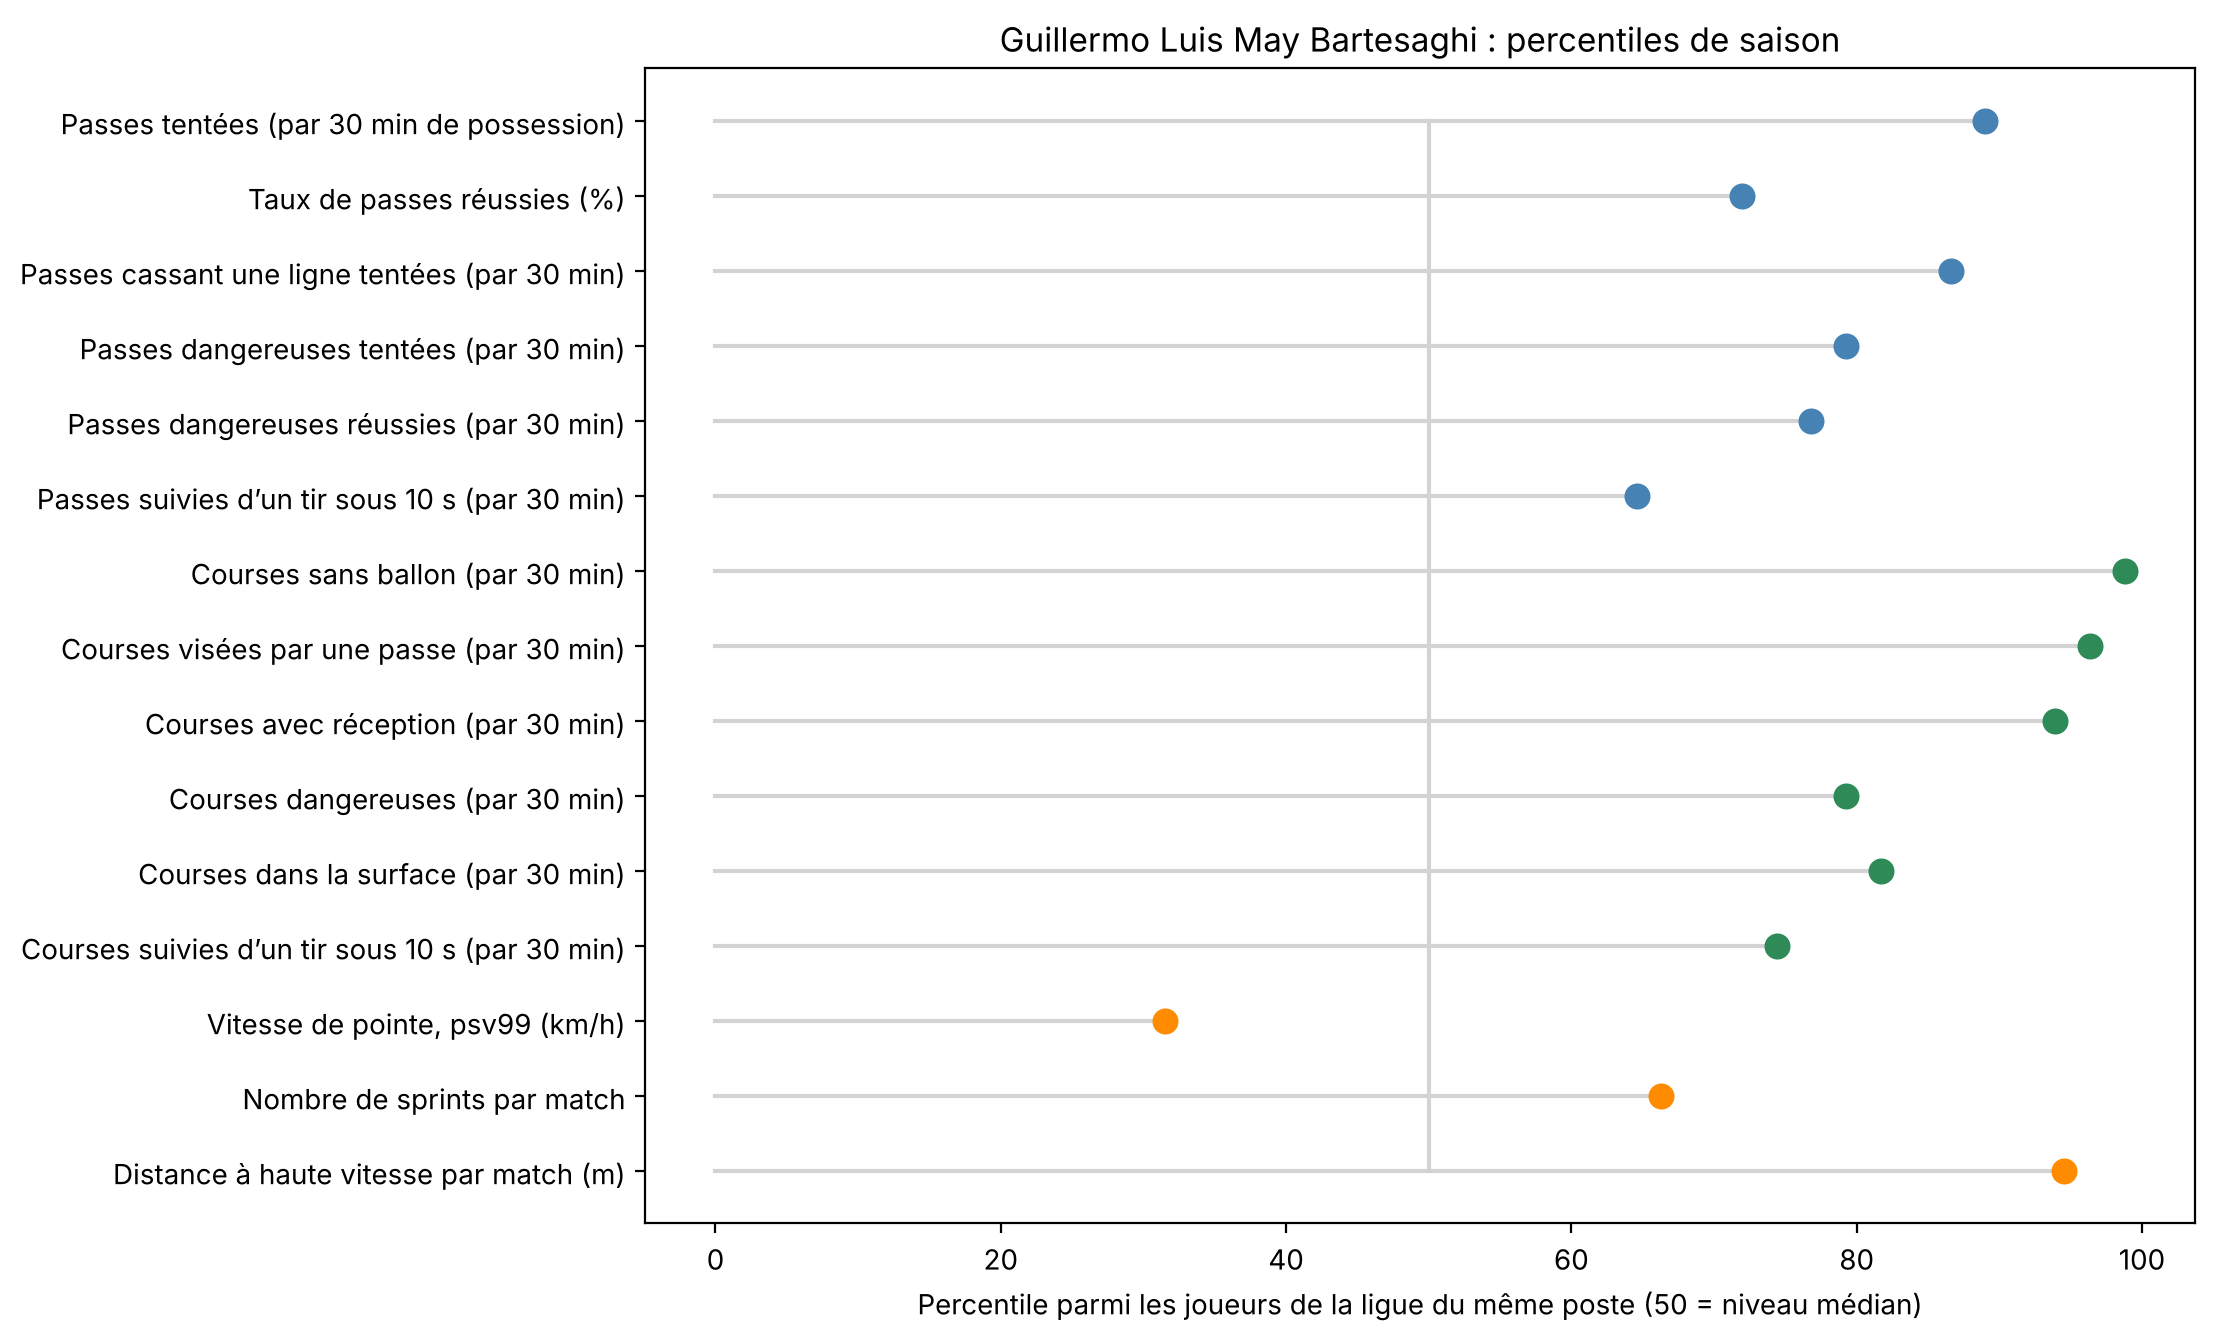

In [ ]:
# %%
joueur = top_joueurs.iloc[0]
graphique_percentiles(percentiles_joueurs, joueur['player_id'],
                      joueur['nom_joueur'] + ' : percentiles de saison', libelles_indicateurs)

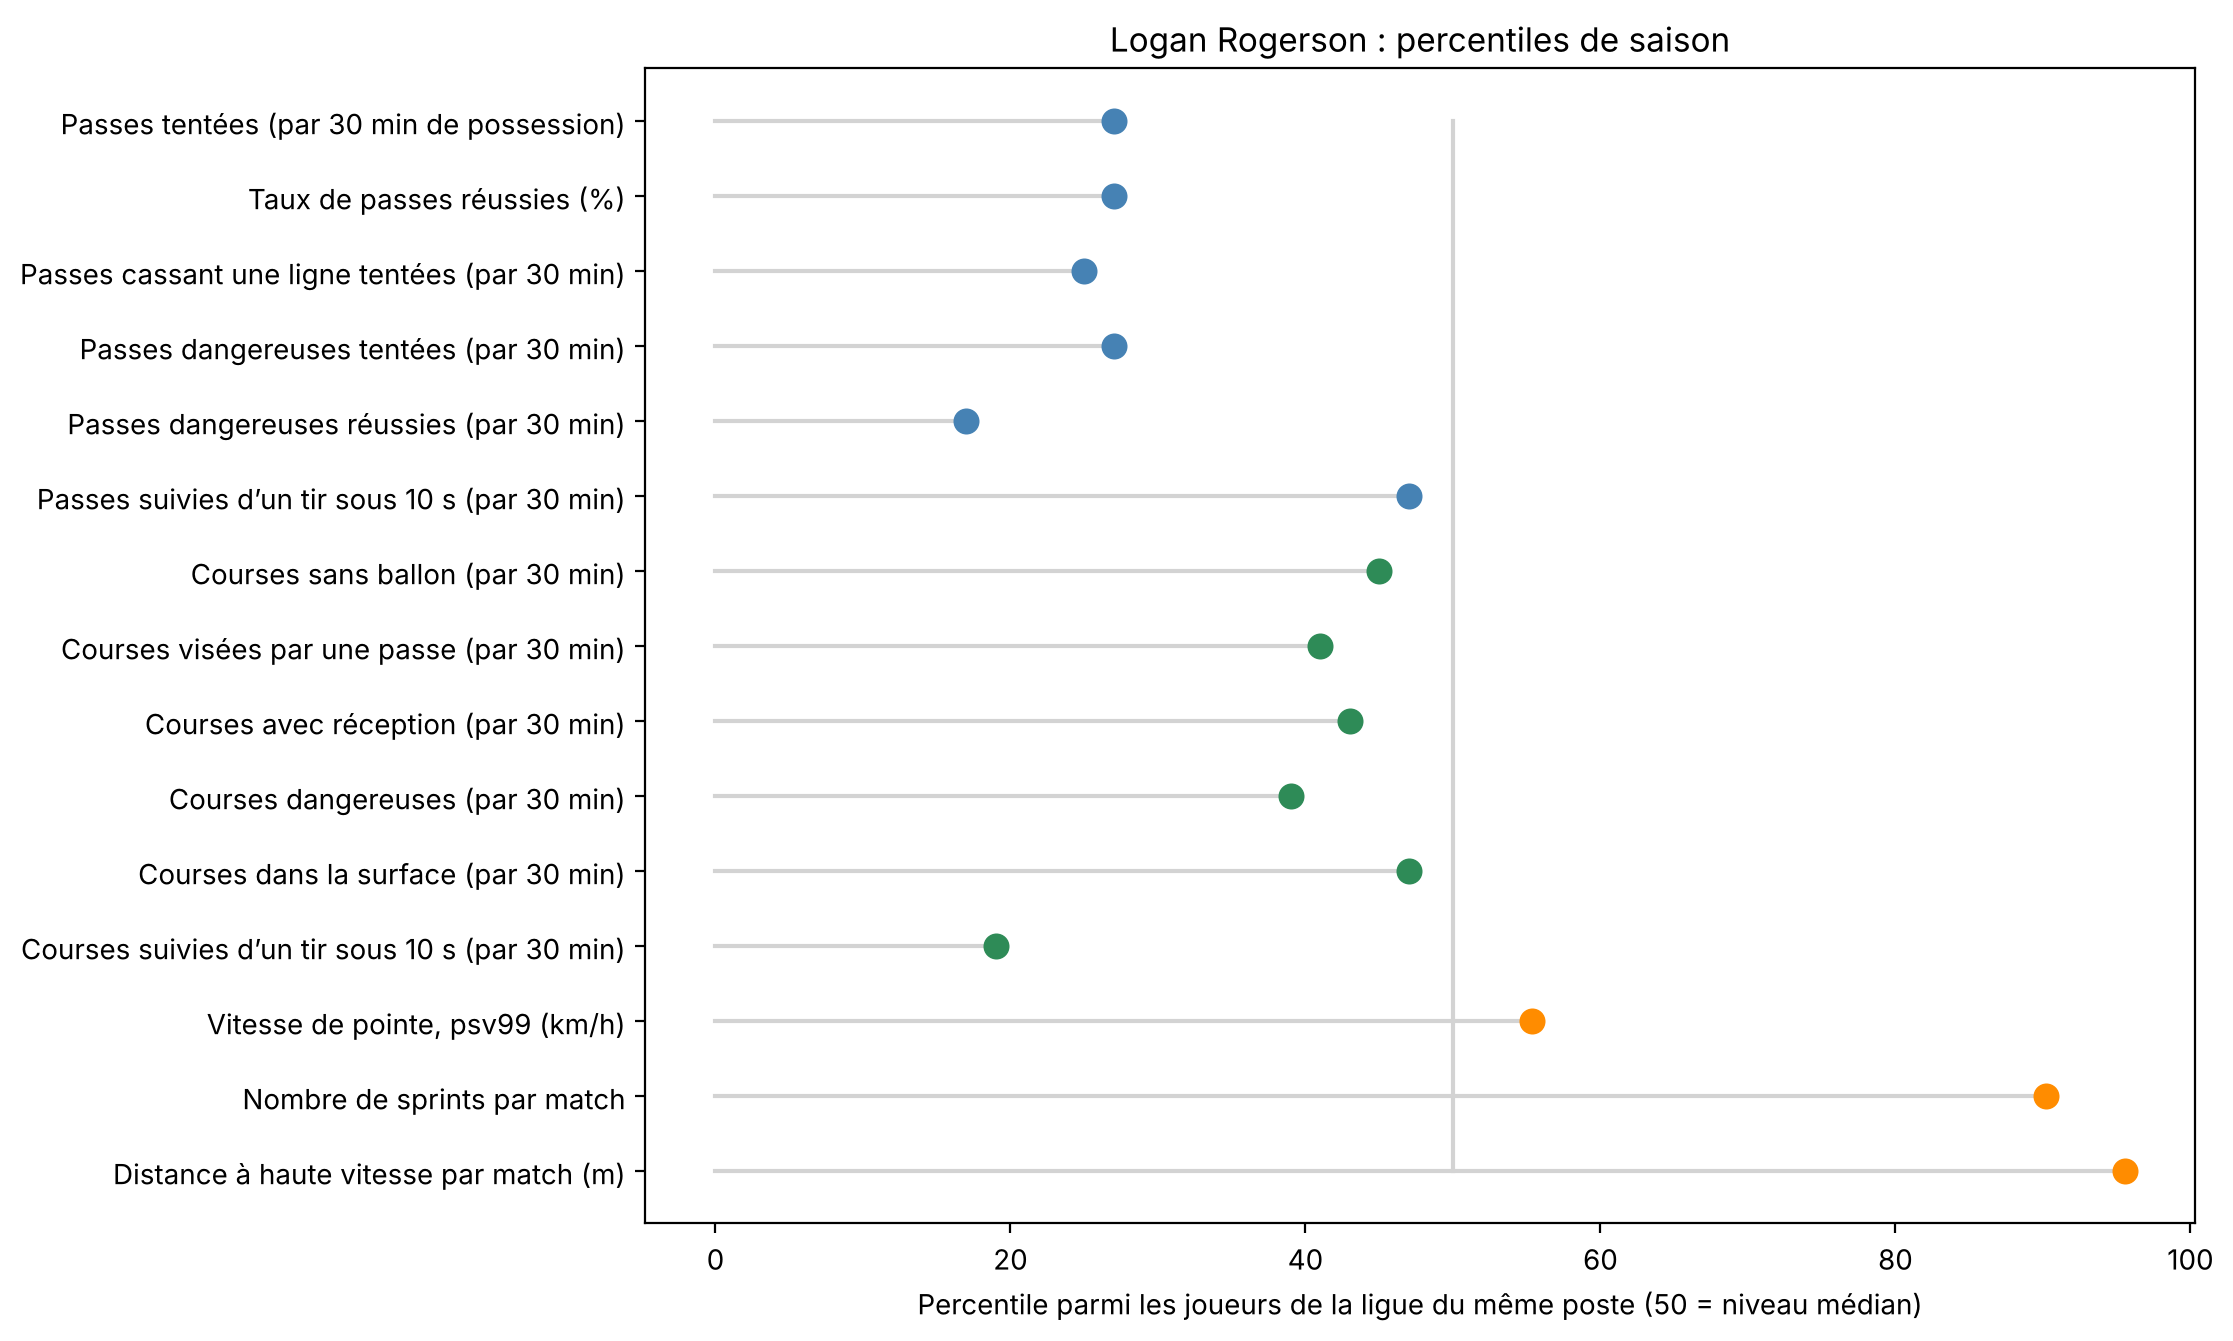

In [ ]:
# %%
joueur = top_joueurs.iloc[1]
graphique_percentiles(percentiles_joueurs, joueur['player_id'],
                      joueur['nom_joueur'] + ' : percentiles de saison', libelles_indicateurs)

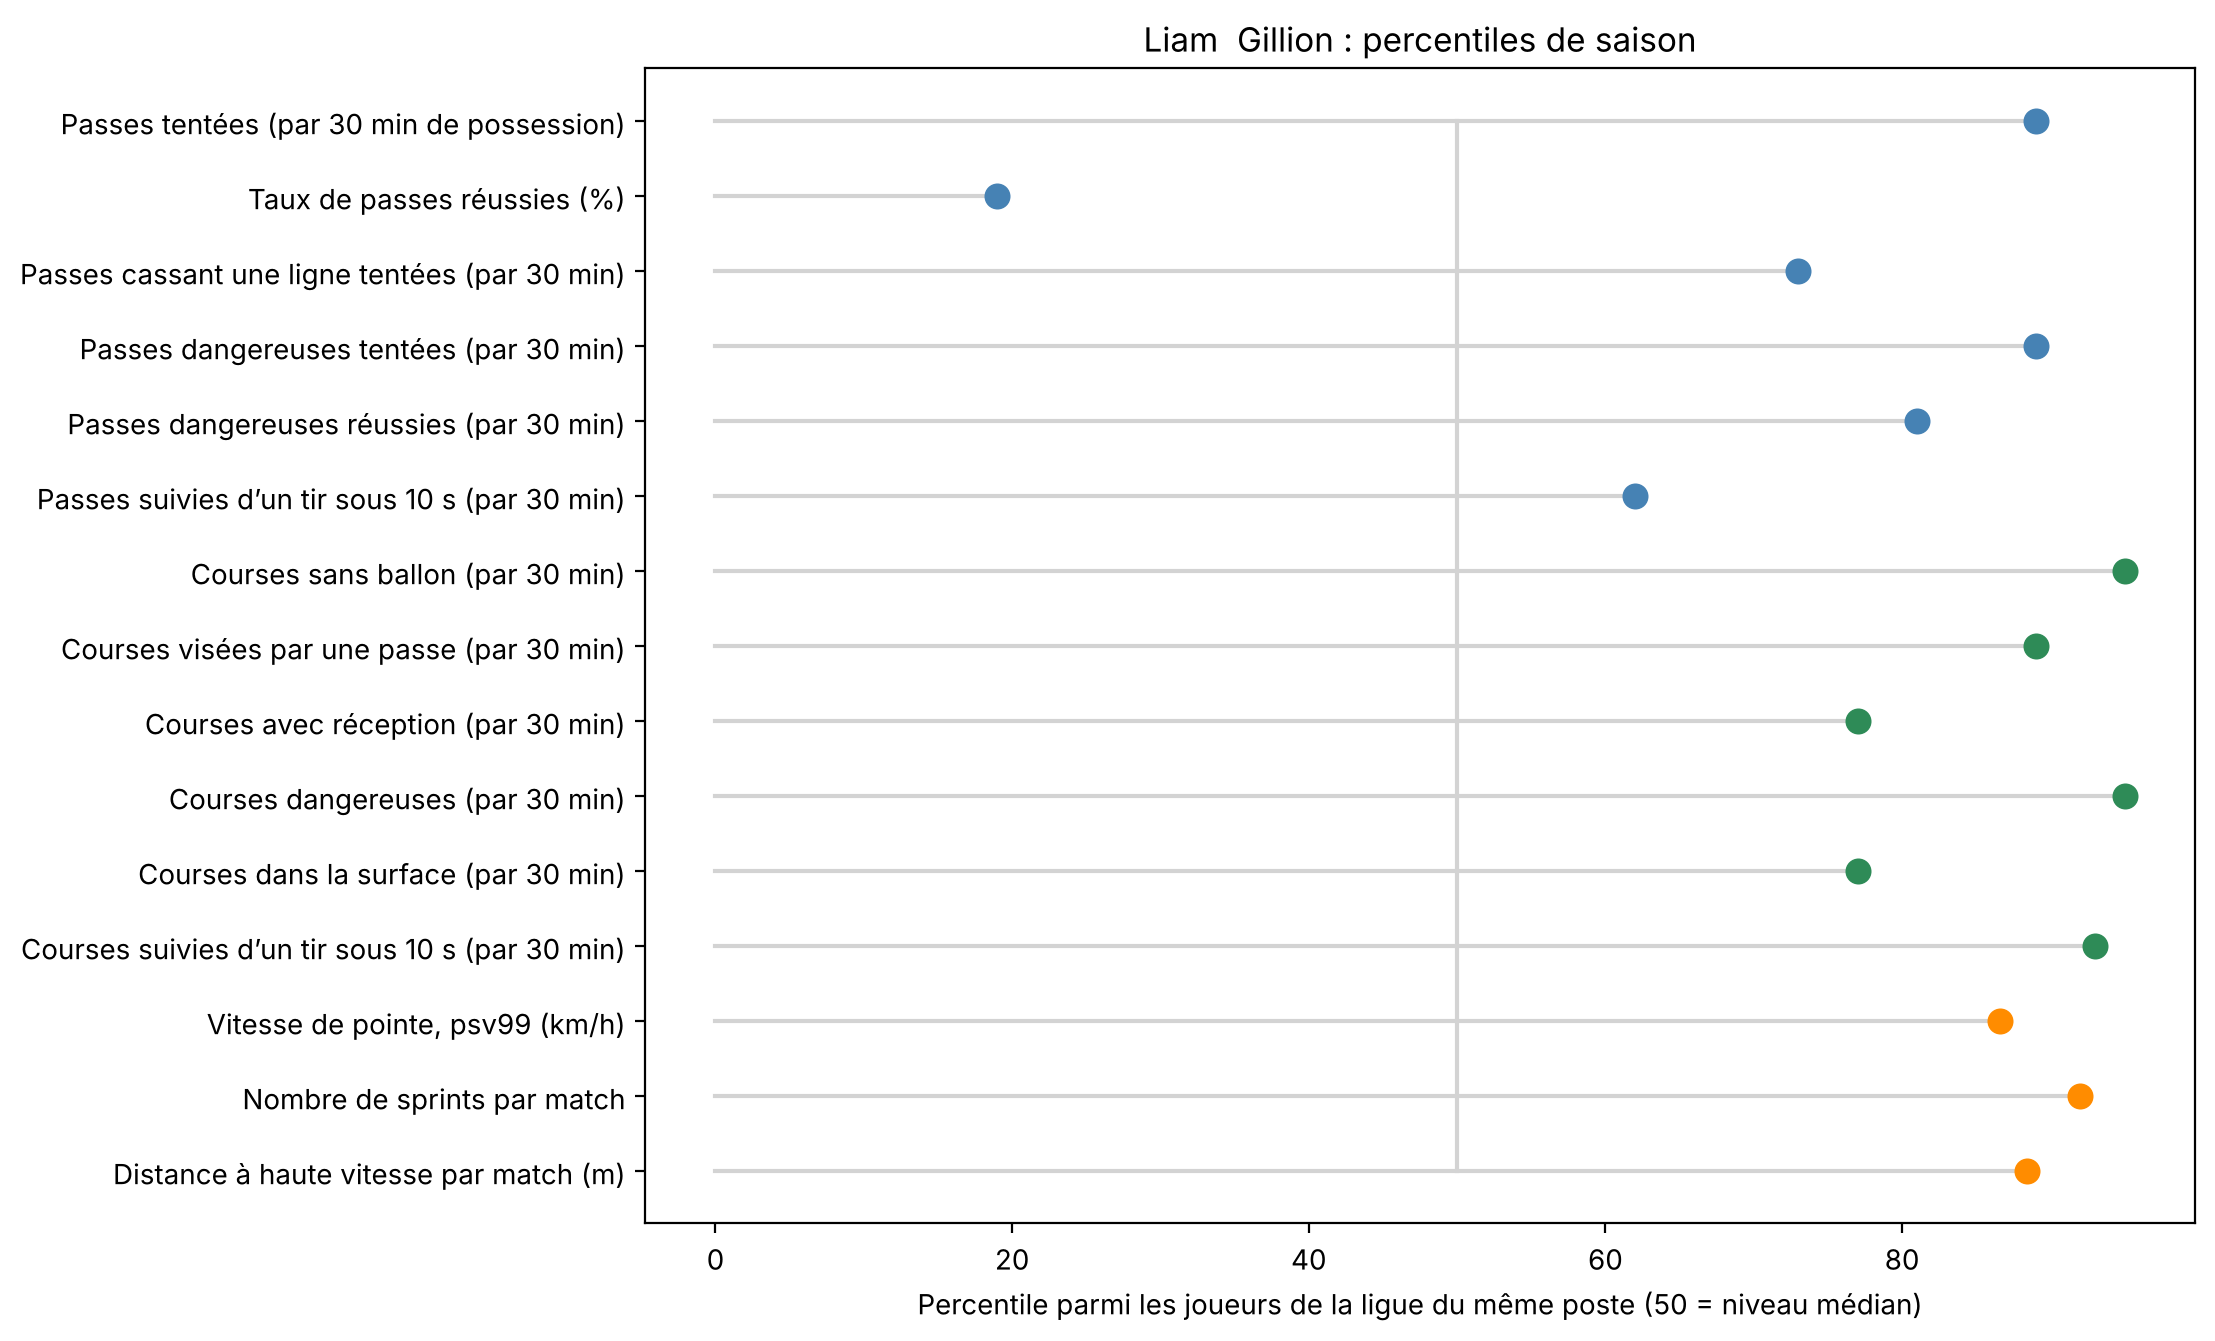

In [ ]:
# %%
joueur = top_joueurs.iloc[2]
graphique_percentiles(percentiles_joueurs, joueur['player_id'],
                      joueur['nom_joueur'] + ' : percentiles de saison', libelles_indicateurs)

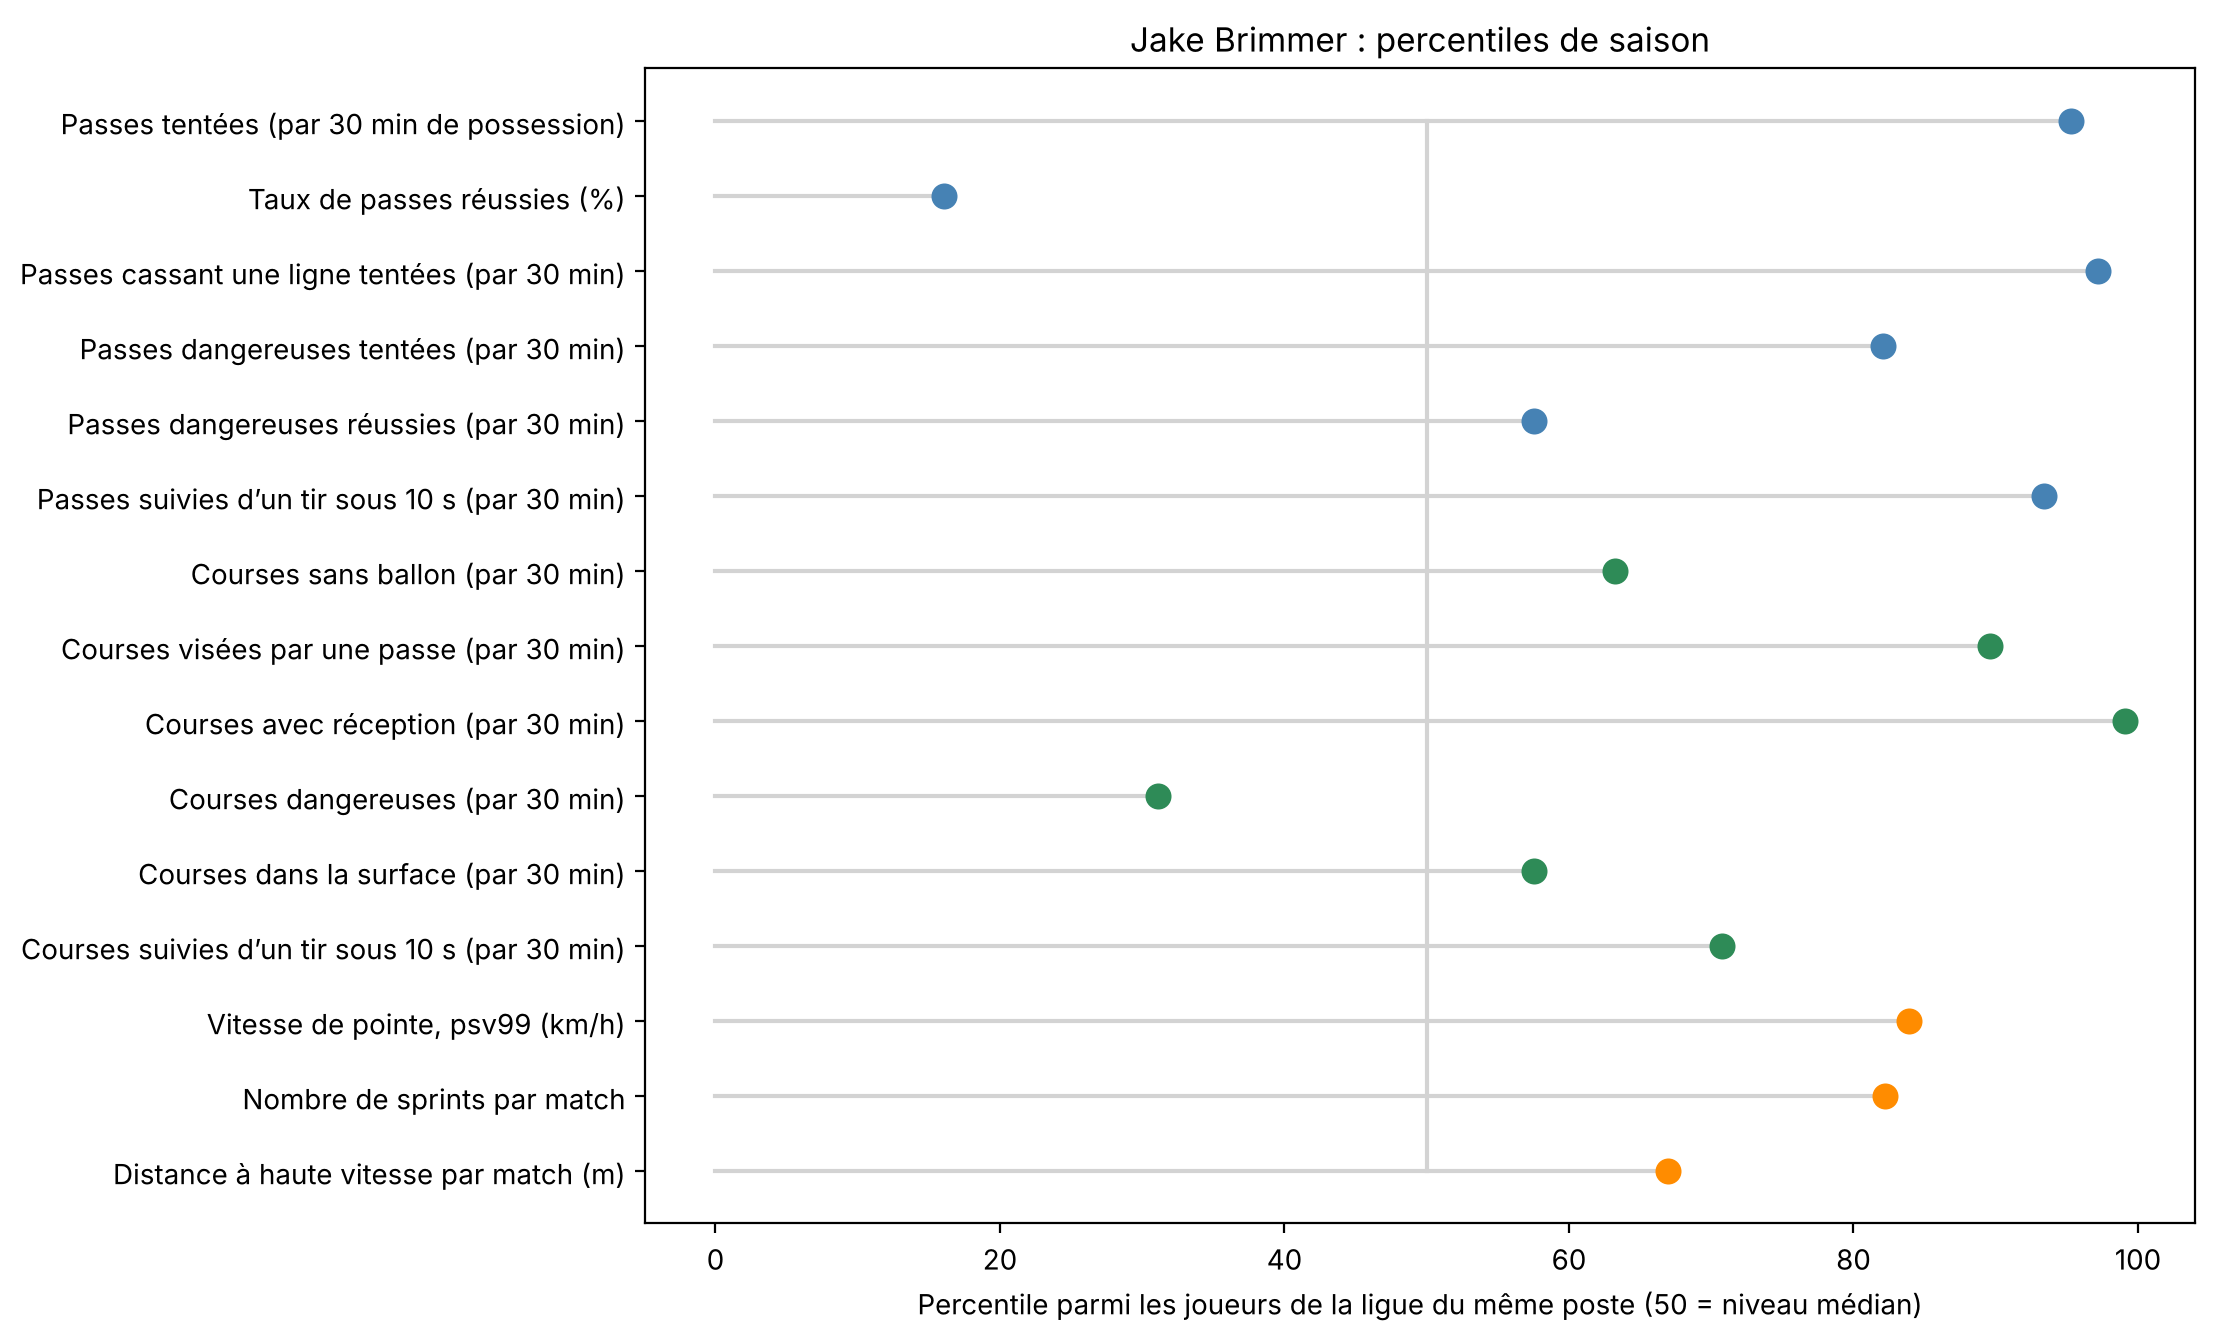

In [ ]:
# %%
joueur = top_joueurs.iloc[3]
graphique_percentiles(percentiles_joueurs, joueur['player_id'],
                      joueur['nom_joueur'] + ' : percentiles de saison', libelles_indicateurs)

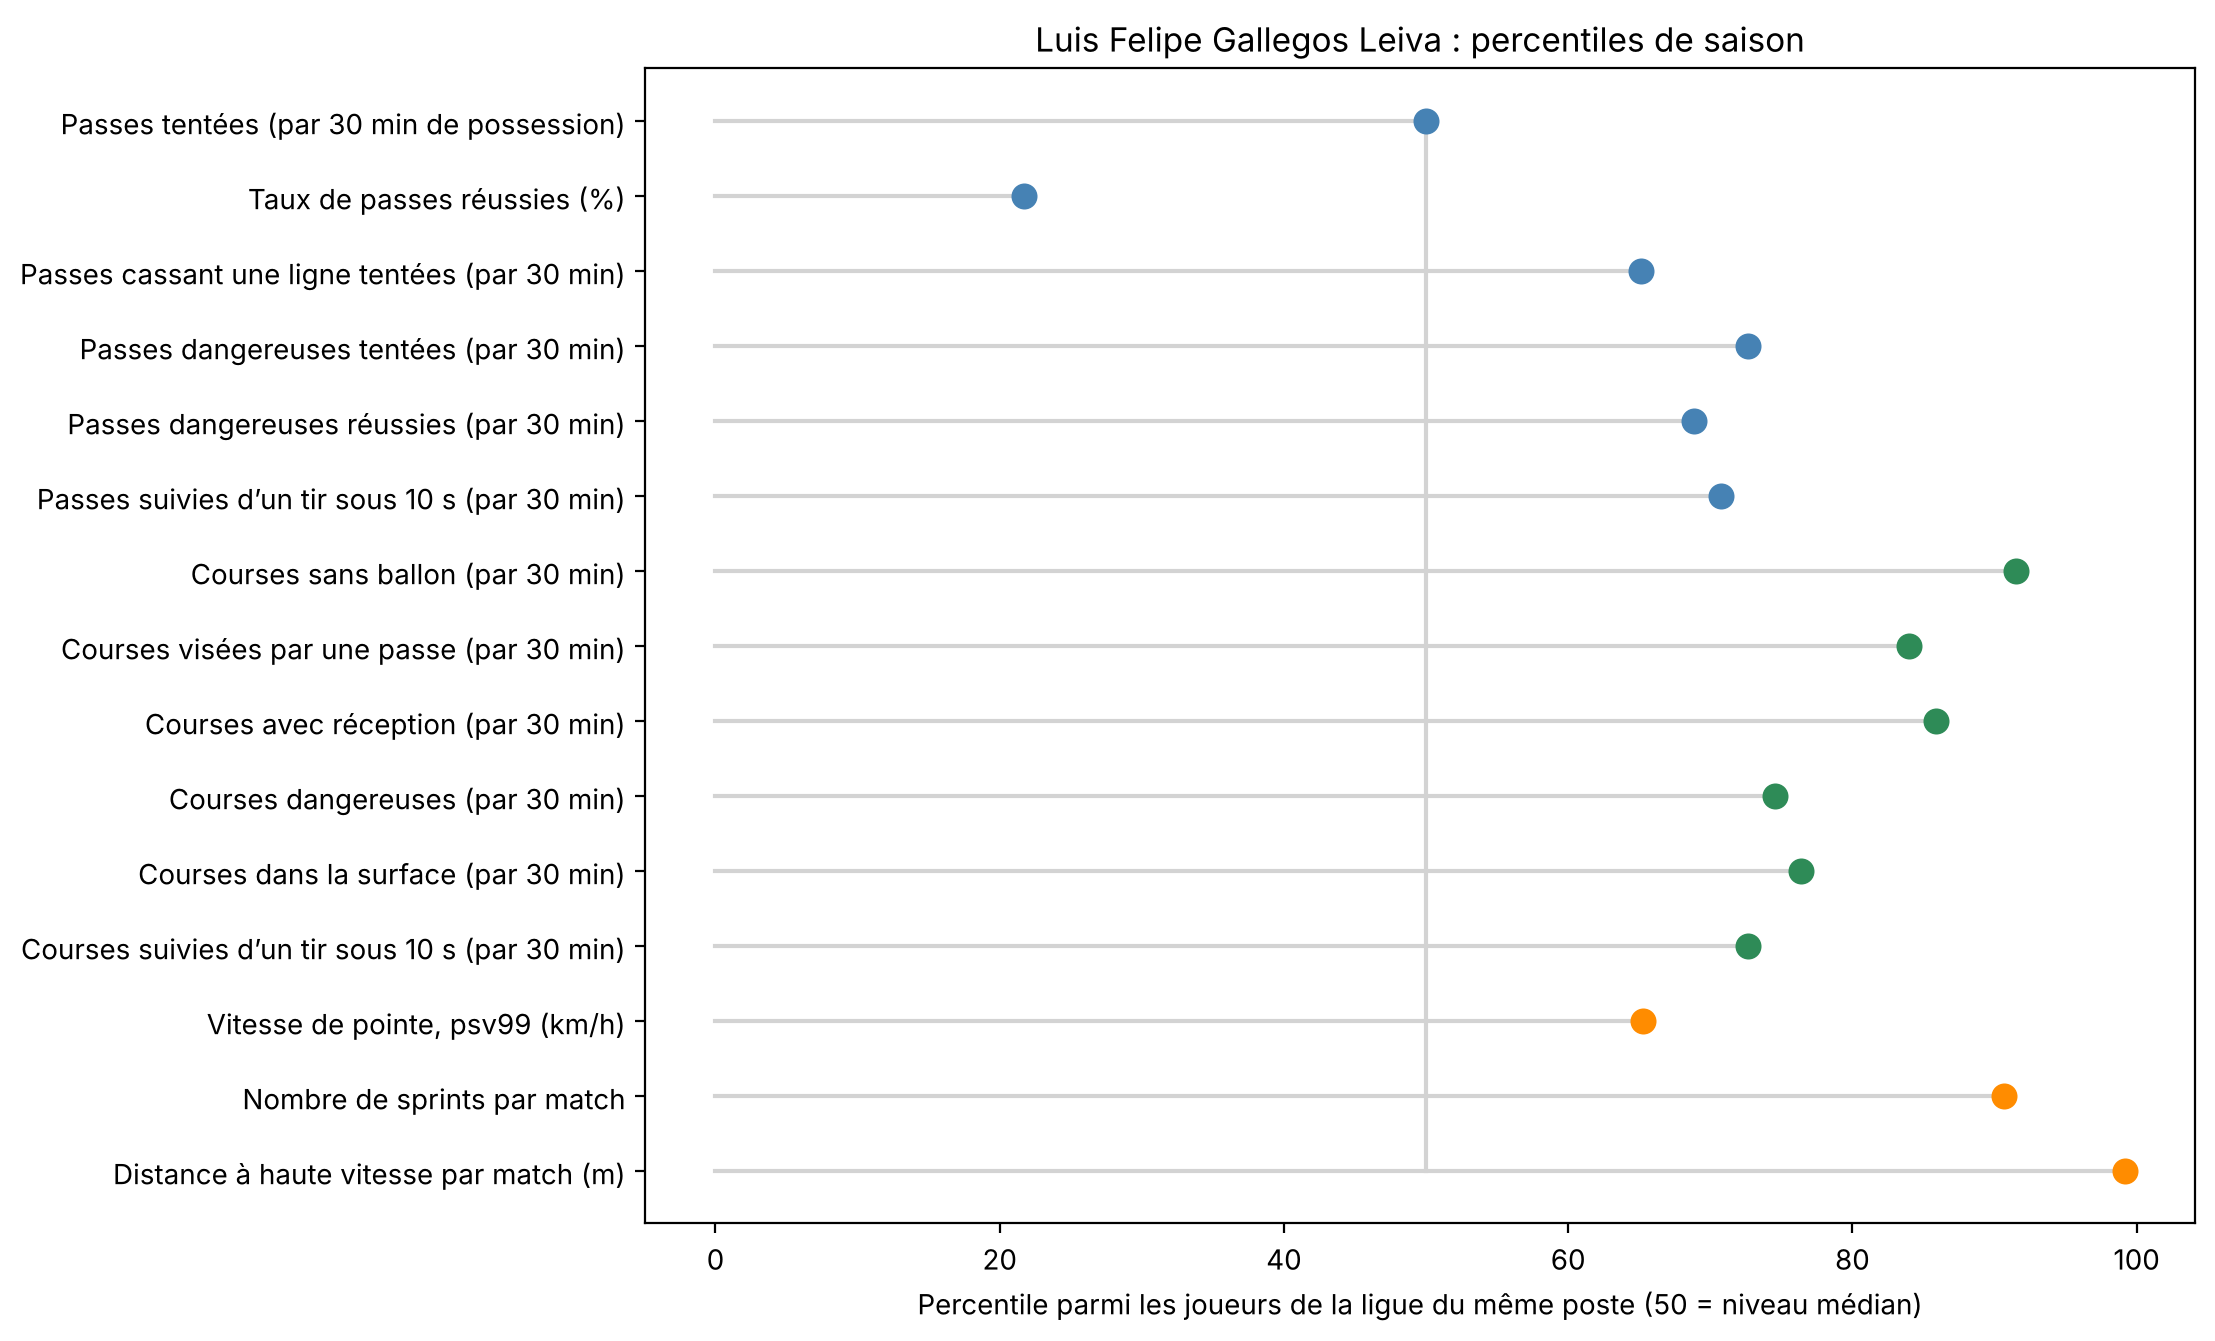

In [ ]:
# %%
joueur = top_joueurs.iloc[4]
graphique_percentiles(percentiles_joueurs, joueur['player_id'],
                      joueur['nom_joueur'] + ' : percentiles de saison', libelles_indicateurs)

**Commentaire à compléter après exécution.** Les comparaisons par poste sont généralement plus pertinentes que celles avec toute la ligue. Les données saisonnières peuvent comporter plusieurs lignes par joueur et poste : comme dans ton code, on conserve pour chaque catégorie la ligne ayant le plus de matchs.

## 7. Résumé des indicateurs associés au danger

Le tableau suivant présente la moyenne des percentiles sur les variables choisies pour décrire le danger offensif. Il s’agit d’un **résumé descriptif**, pas d’un score validé ni d'un modèle.

In [ ]:
# %%
resume_danger = percentiles_joueurs.loc[
    percentiles_joueurs['est_danger'] == True
].groupby('joueur').agg({
    'percentile_coequipiers': 'mean',
    'percentile_ligue_meme_poste': 'mean',
    'percentile_ligue_tous_postes': 'mean'
})

resume_danger.rename(columns={
    'percentile_coequipiers': 'Au sein d’Auckland',
    'percentile_ligue_meme_poste': 'Ligue, même poste',
    'percentile_ligue_tous_postes': 'Ligue, tous postes'
}).round(1)

,Au sein d’Auckland,"Ligue, même poste","Ligue, tous postes"
joueur,,,
Guillermo Luis May Bartesaghi,79.0,77.5,78.8
Jake Brimmer,62.9,69.9,65.3
Liam Gillion,82.6,81.4,82.9
Logan Rogerson,56.7,31.6,60.7
Luis Felipe Gallegos Leiva,62.9,71.6,64.7


## 8. Bilan — Profils saisonniers et zone 14

Cette partie rapproche **l'implication dans la zone 14 sur quatre matchs** et les **statistiques de l'ensemble de la saison**. Le premier classement indique quels joueurs apparaissent le plus souvent dans les actions sélectionnées. Les percentiles permettent ensuite de situer leurs profils de passes, courses et activité physique par rapport à différents groupes de joueurs.

**Interprétation à compléter avec les tableaux calculés :** préciser les trois joueurs retenus, leurs principales forces statistiques et la manière dont leurs profils peuvent éclairer leur utilisation de la zone 14.

**Limites :** quatre matchs ne résument pas une saison ; les volumes ne sont pas ajustés au temps de jeu ; les réceptions de passes sont estimées ; les indicateurs de passes et de courses ne décrivent pas tous le même type d'activité et les percentiles ne démontrent aucun lien de causalité.